## **projet de fin de module Détection de cyberharcèlement**

### Effectué par :
### JORCHE IMANE
### LAABIDI WIDAD

### **uploaded data "train.csv"**

In [ ]:
#uploaded data "train.csv"
from google.colab import files

print("Upload your data")

uploaded = files.upload()
print("your data Upload successfully")

Upload your data


Saving train.csv to train.csv
your data Upload successfully


### **importation des bibliothiques**

In [ ]:

#download NLTK
!pip install nltk -q

#importation des bibliothiques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import nltk
import re
import joblib
import warnings
warnings.filterwarnings('ignore')


nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("importation des bibliothiques terminé !")

importation des bibliothiques terminé !


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


### **Lecture et compréhension des données**

In [ ]:
# Lecture des données
data = pd.read_csv('train.csv')

# Forme des données
print("Forme du dataset :", data.shape)

# Colonnes
print("\nColonnes :", data.columns.tolist())

# Premières lignes
data.head(10)

Forme du dataset : (159571, 8)

Colonnes : ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0


In [ ]:

#vérification des valeures manquantes
data.isnull().sum()

,0
id,0
comment_text,0
toxic,0
severe_toxic,0
obscene,0
threat,0
insult,0
identity_hate,0


In [ ]:
#vérification des valeurs doublons
data.drop_duplicates()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
...,...,...,...,...,...,...,...,...
159566,ffe987279560d7ff,""":::::And for the second time of asking, when ...",0,0,0,0,0,0
159567,ffea4adeee384e90,You should be ashamed of yourself \n\nThat is ...,0,0,0,0,0,0
159568,ffee36eab5c267c9,"Spitzer \n\nUmm, theres no actual article for ...",0,0,0,0,0,0
159569,fff125370e4aaaf3,And it looks like it was actually you who put ...,0,0,0,0,0,0


### **NLP Preprocessing**

In [ ]:

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    # 1. Convertir en string
    text = str(text)
    # 2. Minuscules
    text = text.lower()
    # 3. Supprimer URLs
    text = re.sub(r'http\S+', '', text)
    # 4. Supprimer chiffres et symboles
    text = re.sub(r'[^a-z\s]', '', text)
    # 5. Supprimer espaces en trop
    text = text.strip()
    # 6. Tokenisation
    tokens = text.split()
    # 7. Stopwords + Lemmatisation
    tokens = [lemmatizer.lemmatize(w)
              for w in tokens
              if w not in stop_words
              and len(w) > 2]
    return ' '.join(tokens)

# Créer le label binaire
labels = ['toxic','severe_toxic','obscene',
          'threat','insult','identity_hate']
data['label'] = (data[labels].sum(axis=1) > 0).astype(int)

# Appliquer le preprocessing
print("Preprocessing en cours... (2-3 minutes)")
data['clean_text'] = data['comment_text'].apply(preprocess)
print("Preprocessing terminé !")

# Vérification avant / après
print("\n=== Avant ===")
print(data['comment_text'][6])
print("\n=== Après ===")
print(data['clean_text'][6])

data.head(2)

Preprocessing en cours... (2-3 minutes)
Preprocessing terminé !

=== Avant ===
COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK

=== Après ===
cocksucker piss around work


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,label,clean_text
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,explanation edits made username hardcore metal...
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,daww match background colour seemingly stuck t...


### **TF-IDF**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Split 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    data['clean_text'],
    data['label'],
    test_size=0.2,
    random_state=42,
    stratify=data['label']
)

print(f"Train : {len(X_train):,} commentaires")
print(f"Test  : {len(X_test):,} commentaires")

# TF-IDF
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"\nShape matrix : {X_train_tfidf.shape}")
print("TF-IDF terminé !")

Train : 127,656 commentaires
Test  : 31,915 commentaires

Shape matrix : (127656, 10000)
TF-IDF terminé !


### **Entraînement 3 modèles**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score)

# Définition des modèles
models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, C=1.0),
    'Naive Bayes'         : MultinomialNB(alpha=0.1),
    'LinearSVC'           : LinearSVC(max_iter=1000)
}

results = {}
trained_models = {}

for name, model in models.items():
    print(f"Entraînement de {name}...")

    # Entraînement
    model.fit(X_train_tfidf, y_train)

    # Prédiction
    y_pred = model.predict(X_test_tfidf)

    # Métriques
    results[name] = {
        'Accuracy' : round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall'   : round(recall_score(y_test, y_pred), 4),
        'F1-Score' : round(f1_score(y_test, y_pred), 4)
    }

    trained_models[name] = model
    print(f"{name} terminé !")

print("\nTous les modèles entraînés !")

Entraînement de Logistic Regression...
Logistic Regression terminé !
Entraînement de Naive Bayes...
Naive Bayes terminé !
Entraînement de LinearSVC...
LinearSVC terminé !

Tous les modèles entraînés !


### **Comparaison + Métriques**

       COMPARAISON DES MODÈLES
                     Accuracy  Precision  Recall  F1-Score
Logistic Regression     0.957     0.9157  0.6361    0.7507
Naive Bayes             0.950     0.9017  0.5707    0.6990
LinearSVC               0.959     0.8732  0.6983    0.7760


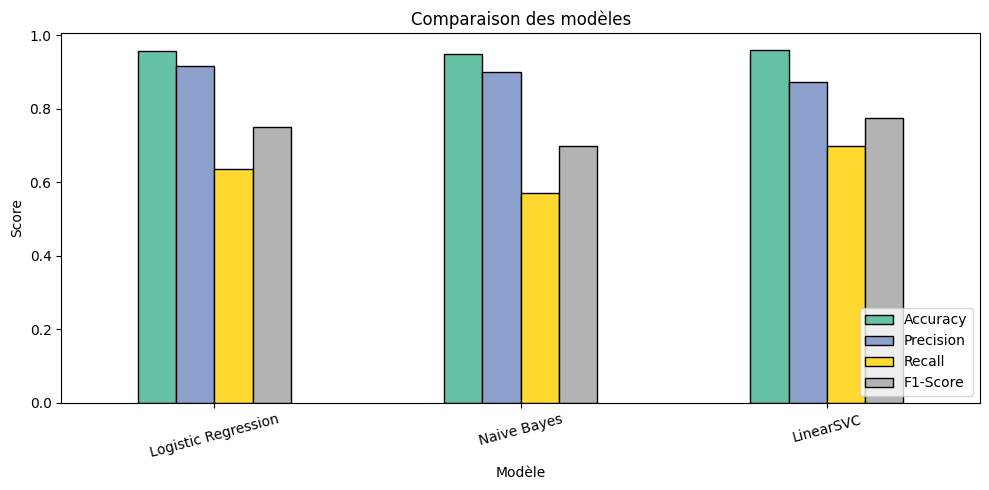

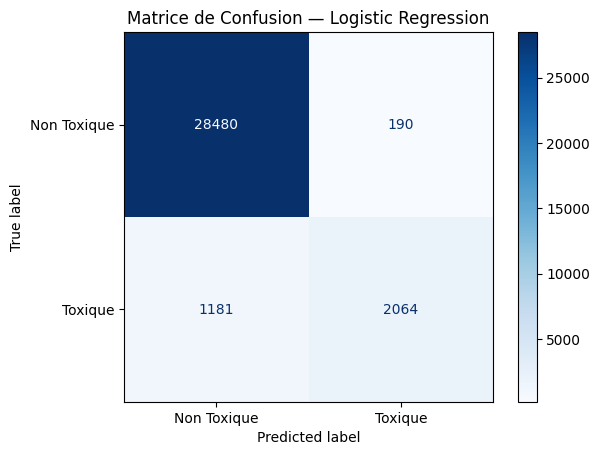


=== Rapport de Classification ===
              precision    recall  f1-score   support

 Non Toxique       0.96      0.99      0.98     28670
     Toxique       0.92      0.64      0.75      3245

    accuracy                           0.96     31915
   macro avg       0.94      0.81      0.86     31915
weighted avg       0.96      0.96      0.95     31915



In [ ]:
from sklearn.metrics import (classification_report,
                              confusion_matrix,
                              ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import pandas as pd

# Tableau comparatif
results_df = pd.DataFrame(results).T
print("="*55)
print("       COMPARAISON DES MODÈLES")
print("="*55)
print(results_df.to_string())
print("="*55)

# Graphique comparaison
results_df.plot(
    kind='bar',
    figsize=(10, 5),
    edgecolor='black',
    colormap='Set2'
)
plt.title("Comparaison des modèles")
plt.xlabel("Modèle")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Meilleur modèle = Logistic Regression
best_model = trained_models['Logistic Regression']
y_pred_best = best_model.predict(X_test_tfidf)

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(
    cm,
    display_labels=['Non Toxique', 'Toxique']
)
disp.plot(cmap='Blues')
plt.title("Matrice de Confusion — Logistic Regression")
plt.show()

# Rapport complet
print("\n=== Rapport de Classification ===")
print(classification_report(
    y_test, y_pred_best,
    target_names=['Non Toxique', 'Toxique']
))

### **WordCloud**

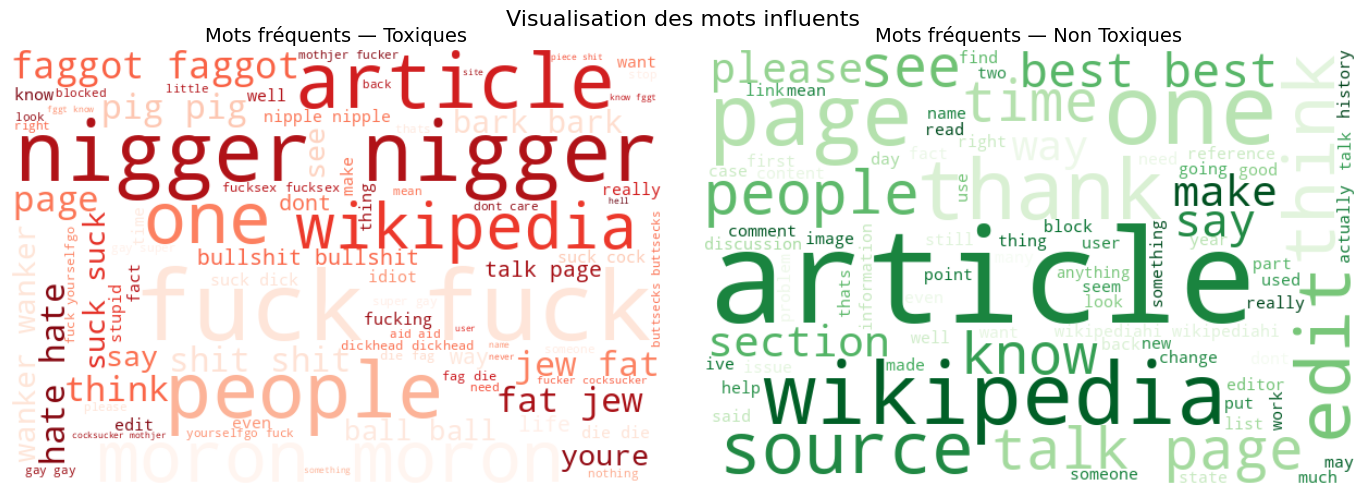

WordCloud terminé !


In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Textes toxic et non toxic
toxic_text     = ' '.join(data[data['label']==1]['clean_text'])
non_toxic_text = ' '.join(
    data[data['label']==0]['clean_text'].sample(5000, random_state=42)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# WordCloud Toxique
wc1 = WordCloud(
    width=600, height=400,
    background_color='white',
    colormap='Reds',
    max_words=80
).generate(toxic_text)

axes[0].imshow(wc1, interpolation='bilinear')
axes[0].set_title("Mots fréquents — Toxiques", fontsize=14)
axes[0].axis('off')

# WordCloud Non Toxique
wc2 = WordCloud(
    width=600, height=400,
    background_color='white',
    colormap='Greens',
    max_words=80
).generate(non_toxic_text)

axes[1].imshow(wc2, interpolation='bilinear')
axes[1].set_title("Mots fréquents — Non Toxiques", fontsize=14)
axes[1].axis('off')

plt.suptitle("Visualisation des mots influents", fontsize=16)
plt.tight_layout()
plt.show()

print("WordCloud terminé !")

### **Sauvegarde et téléchargement du modèle**

In [ ]:
import joblib
from google.colab import files

# Sauvegarde
joblib.dump(best_model, 'model.pkl')
joblib.dump(tfidf,      'tfidf.pkl')
print("Modèle sauvegardé !")

# Téléchargement vers PC
files.download('model.pkl')
files.download('tfidf.pkl')
print("model.pkl et tfidf.pkl téléchargés !")

Modèle sauvegardé !


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

model.pkl et tfidf.pkl téléchargés !
